# Threshold Accepting (TA) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

Threshold accepting allows bounded deterioration early in the search without a probabilistic annealing rule.

1. Start at the best shared initial candidate and propose a reflected fixed-length random step.
2. Decrease the initial threshold linearly to zero with post-initialization budget progress.
3. Accept if `log(1+trial_fitness) <= log(1+current_fitness) + threshold`.
4. Update the independent best archive after every evaluation.
5. Continue to the exact budget of 3,264 unique evaluations.

Unlike great deluge's absolute water level, the threshold is relative to the current point's transformed fitness. Late in the run, acceptance approaches a non-worsening rule.

Read [methods.py](../pid%20using%20threshold%20accepting/methods.py) for the implemented update rules, [config.json](../pid%20using%20threshold%20accepting/config.json) for settings, and [study.py](../pid%20using%20threshold%20accepting/study.py) for objective evaluation.


In [2]:
METHOD='TA'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,"Sampled robustness tuning: inertia, motor dynamics and damping"
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2])


"""Six explicitly specified bounded continuous-search variants.
All operate in normalized log-gain coordinates; the original objective is unchanged.
"""
from pathlib import Path
import json,time,hashlib
import numpy as np
from benchmark import Budget,BudgetExhausted,initial_population
from study import decode
METHODS=['GDA','TA','ALNS','VND','SBRS','PRW']
FULL_NAMES={'GDA':'Great Deluge Algorithm','TA':'Threshold Accepting','ALNS':'Adaptive Large Neighborhood Search','VND':'Variable Neighborhood Descent (budgeted multistart)','SBRS':'Shrinking Ball Random Search','PRW':'Pure Random Walk (constant proposal step)'}
SEEDS=[11,29,47]+list(range(101,128))
PILOT_SEEDS=[5011,5021,5039]

def reflect(x):
    y=np.mod(x,2.);return np.where(y<=1.,y,2.-y)

def direction(rng,d):
    while True:
        z=rng.normal(size=d);norm=np.linalg.norm(z)
        if norm>0:return z/norm

def merit(f):return float(np.log1p(f))

def accept(method,current,trial,level):
    if method=='PRW':return True
    if method=='GDA':return trial<=current or merit(trial)<=level
    if method in ['TA','ALNS']:return merit(trial)<=merit(current)+level
    return trial<current

def parameter_grid(method):
    if method=='GDA':return [{'step':s,'water_slack':a} for s in [.03,.12] for a in [.05,.25]]
    if method=='TA':return [{'step':s,'threshold0':a} for s in [.03,.12] for a in [.02,.20]]
    if method=='ALNS':return [{'repair_sigma':s,'reaction':r,'threshold0':.05,'segment':64} for s in [.04,.16] for r in [.1,.4]]
    if method=='VND':return [{'radius':r,'neighborhood_order':o} for r in [.05,.20] for o in ['large_to_small','small_to_large']]
    if method=='SBRS':return [{'radius0':r,'radius_ratio':q} for r in [.15,.50] for q in [.01,.1]]
    if method=='PRW':return [{'step':r} for r in [.01,.04,.12,.30]]
    raise ValueError(method)

def optimize(method,seed,cfg,params,out=None,limit=3264,objective=None):
    if method not in METHODS:raise ValueError(method)
    if limit<65:raise ValueError('At least 65 evaluations required for shared initialization plus search')
    rng,x0=initial_population(seed,cfg);init_hash=hashlib.sha256(x0.tobytes()).hexdigest()
    b=Budget(cfg,limit,None,objective);events=[];restarts=0;accepted=0
    try:
        f0=b.score(x0);idx=int(np.argmin(f0));x=x0[idx].copy();f=float(f0[idx]);initial_best=f
        water0=merit(f)+params.get('water_slack',0.)
        wd=np.ones(4);wr=np.ones(3);sd=np.zeros(4);sr=np.zeros(3);nd=np.zeros(4);nr=np.zeros(3)
        radii=params.get('radius',.1)*np.array([1.,.5,.1,.02])
        if params.get('neighborhood_order')=='small_to_large':radii=radii[::-1]
        k=0;coord=0;cycle_start=x.copy()
        while True:
            b.iteration+=1;p=b.progress();level=0.;opd=-1;opr=-1;restart=False
            if method in ['GDA','TA','PRW']:
                trial=reflect(x+params['step']*direction(rng,len(x)))
                level=water0*(1-p) if method=='GDA' else params.get('threshold0',0.)*(1-p)
            elif method=='SBRS':
                radius=params['radius0']*params['radius_ratio']**p
                trial=reflect(x+radius*rng.random()**(1/len(x))*direction(rng,len(x)))
                level=radius
            elif method=='VND':
                if k==len(radii):
                    trial=rng.random(len(x));restart=True;restarts+=1;level=-1.
                else:
                    trial=x.copy();trial[coord//2]+=radii[k]*(1 if coord%2==0 else -1);trial=reflect(trial);level=float(radii[k])
            else:
                opd=int(rng.choice(4,p=wd/wd.sum()));opr=int(rng.choice(3,p=wr/wr.sum()))
                dims=rng.choice(len(x),[1,2,4,8][opd],replace=False);trial=x.copy()
                if opr==0:trial[dims]=rng.random(len(dims))
                elif opr==1:trial[dims]+=rng.normal(0,params['repair_sigma'],len(dims))
                else:
                    elite=np.array([row[4:] for row in sorted(b.ledger,key=lambda row:row[2])[:16]])
                    a,c,d=elite[rng.choice(len(elite),3,r

## Development selection
Four settings were tested on seeds 5011, 5021, and 5039 in both regimes. One setting was frozen before the 30 main seeds. This extra development budget prevents a claim of equal total effort versus the original five methods.


In [4]:
show_table(load_csv(FOLDER/'results/parameter_selection.csv'))
print('Frozen parameters:',load_json(FOLDER/'results/selected_parameters.json')[METHOD])
show_table(load_csv(FOLDER/'results/selected_candidates.csv'),['mode','selection','seed','fitness','mc_passes','boundary_passes','combined_passes','corner_passes'])


method,candidate,mean_rank,selected,parameters,nominal_median_fitness,robust_median_fitness
TA,0,1.0,True,"{""step"": 0.03, ""threshold0"": 0.02}",0.054821322404183,0.06734375916944502
TA,1,4.0,False,"{""step"": 0.03, ""threshold0"": 0.2}",0.12920566115534265,0.1076201123372912
TA,2,2.1666666666666665,False,"{""step"": 0.12, ""threshold0"": 0.02}",0.05555864546255071,0.06901297679511775
TA,3,2.8333333333333335,False,"{""step"": 0.12, ""threshold0"": 0.2}",0.062000252561401716,0.07536927912945245


Frozen parameters: {'step': 0.03, 'threshold0': 0.02}


mode,selection,seed,fitness,mc_passes,boundary_passes,combined_passes,corner_passes
nominal,best,102,0.05239208857502537,298,51,0,1216
nominal,median,119,0.05539432601702535,298,51,0,1216
robust,best,126,0.06633302640856852,300,53,0,1408
robust,median,118,0.06955378121727943,300,53,0,1344


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
TA,nominal,30,0.05239208857502537,0.055345628941163696,0.05749852025088501,0.004806176024930643,30
TA,robust,30,0.06633302640856852,0.06937906883343675,34.05580099701246,186.04031278455037,29


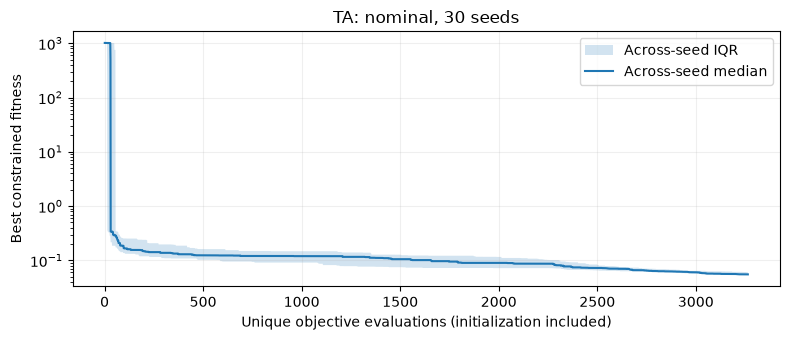

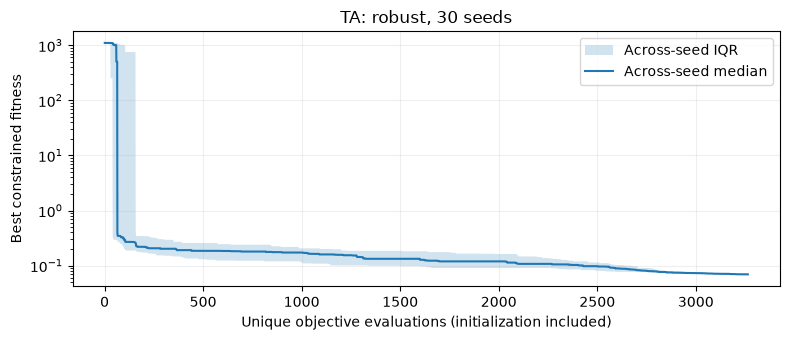

In [5]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [6]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
TA,nominal,Random single-axis,300,276,298.0,300
TA,nominal,One-factor boundaries,54,46,51.0,52
TA,nominal,Combined-axis stress,90,0,0.0,0
TA,robust,Random single-axis,300,298,300.0,300
TA,robust,One-factor boundaries,54,39,53.0,54
TA,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**pid using threshold accepting/results/plots/01_fitness_distributions.png**

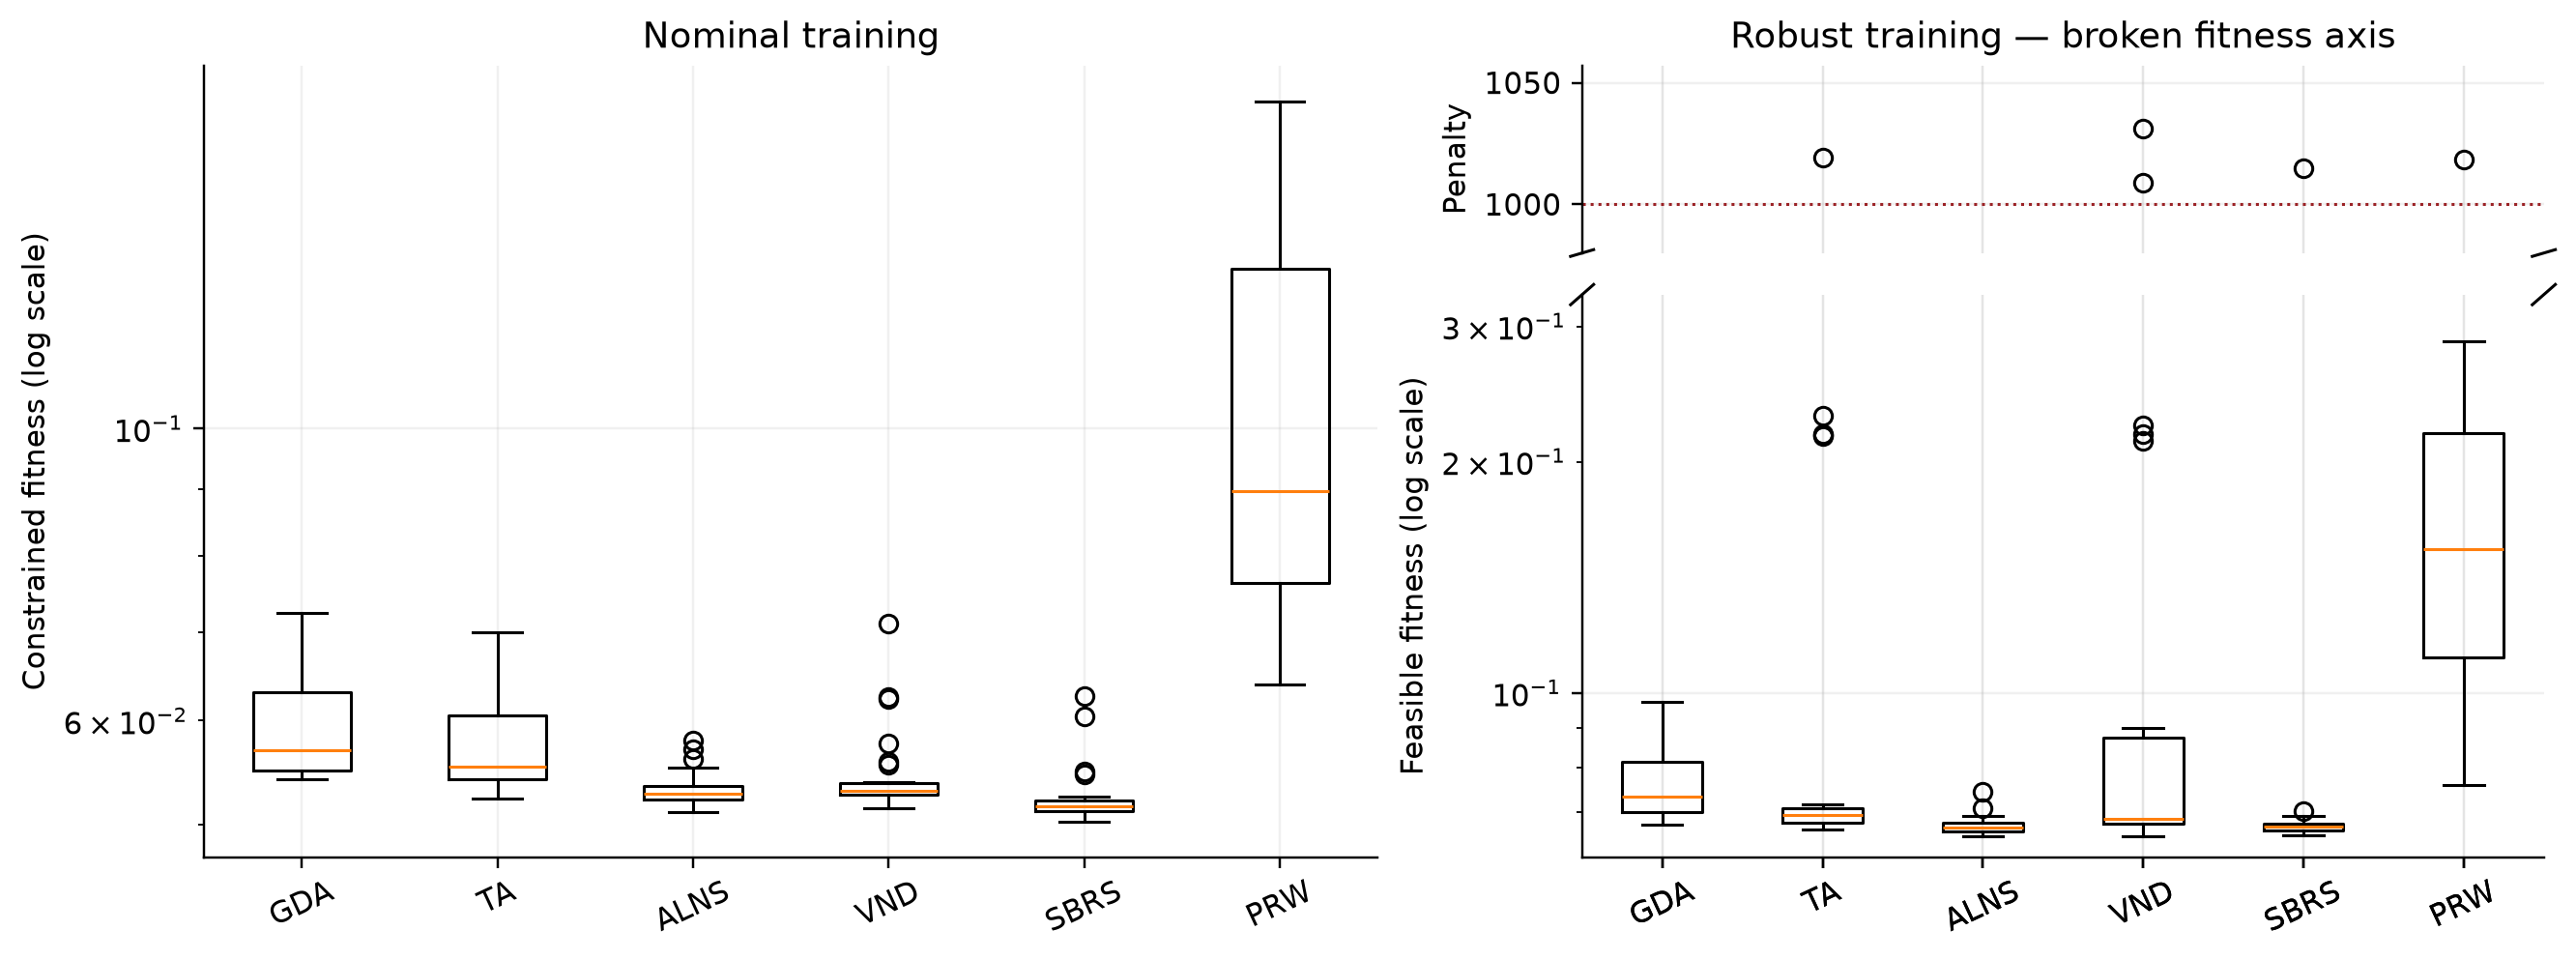

**pid using threshold accepting/results/plots/02_convergence.png**

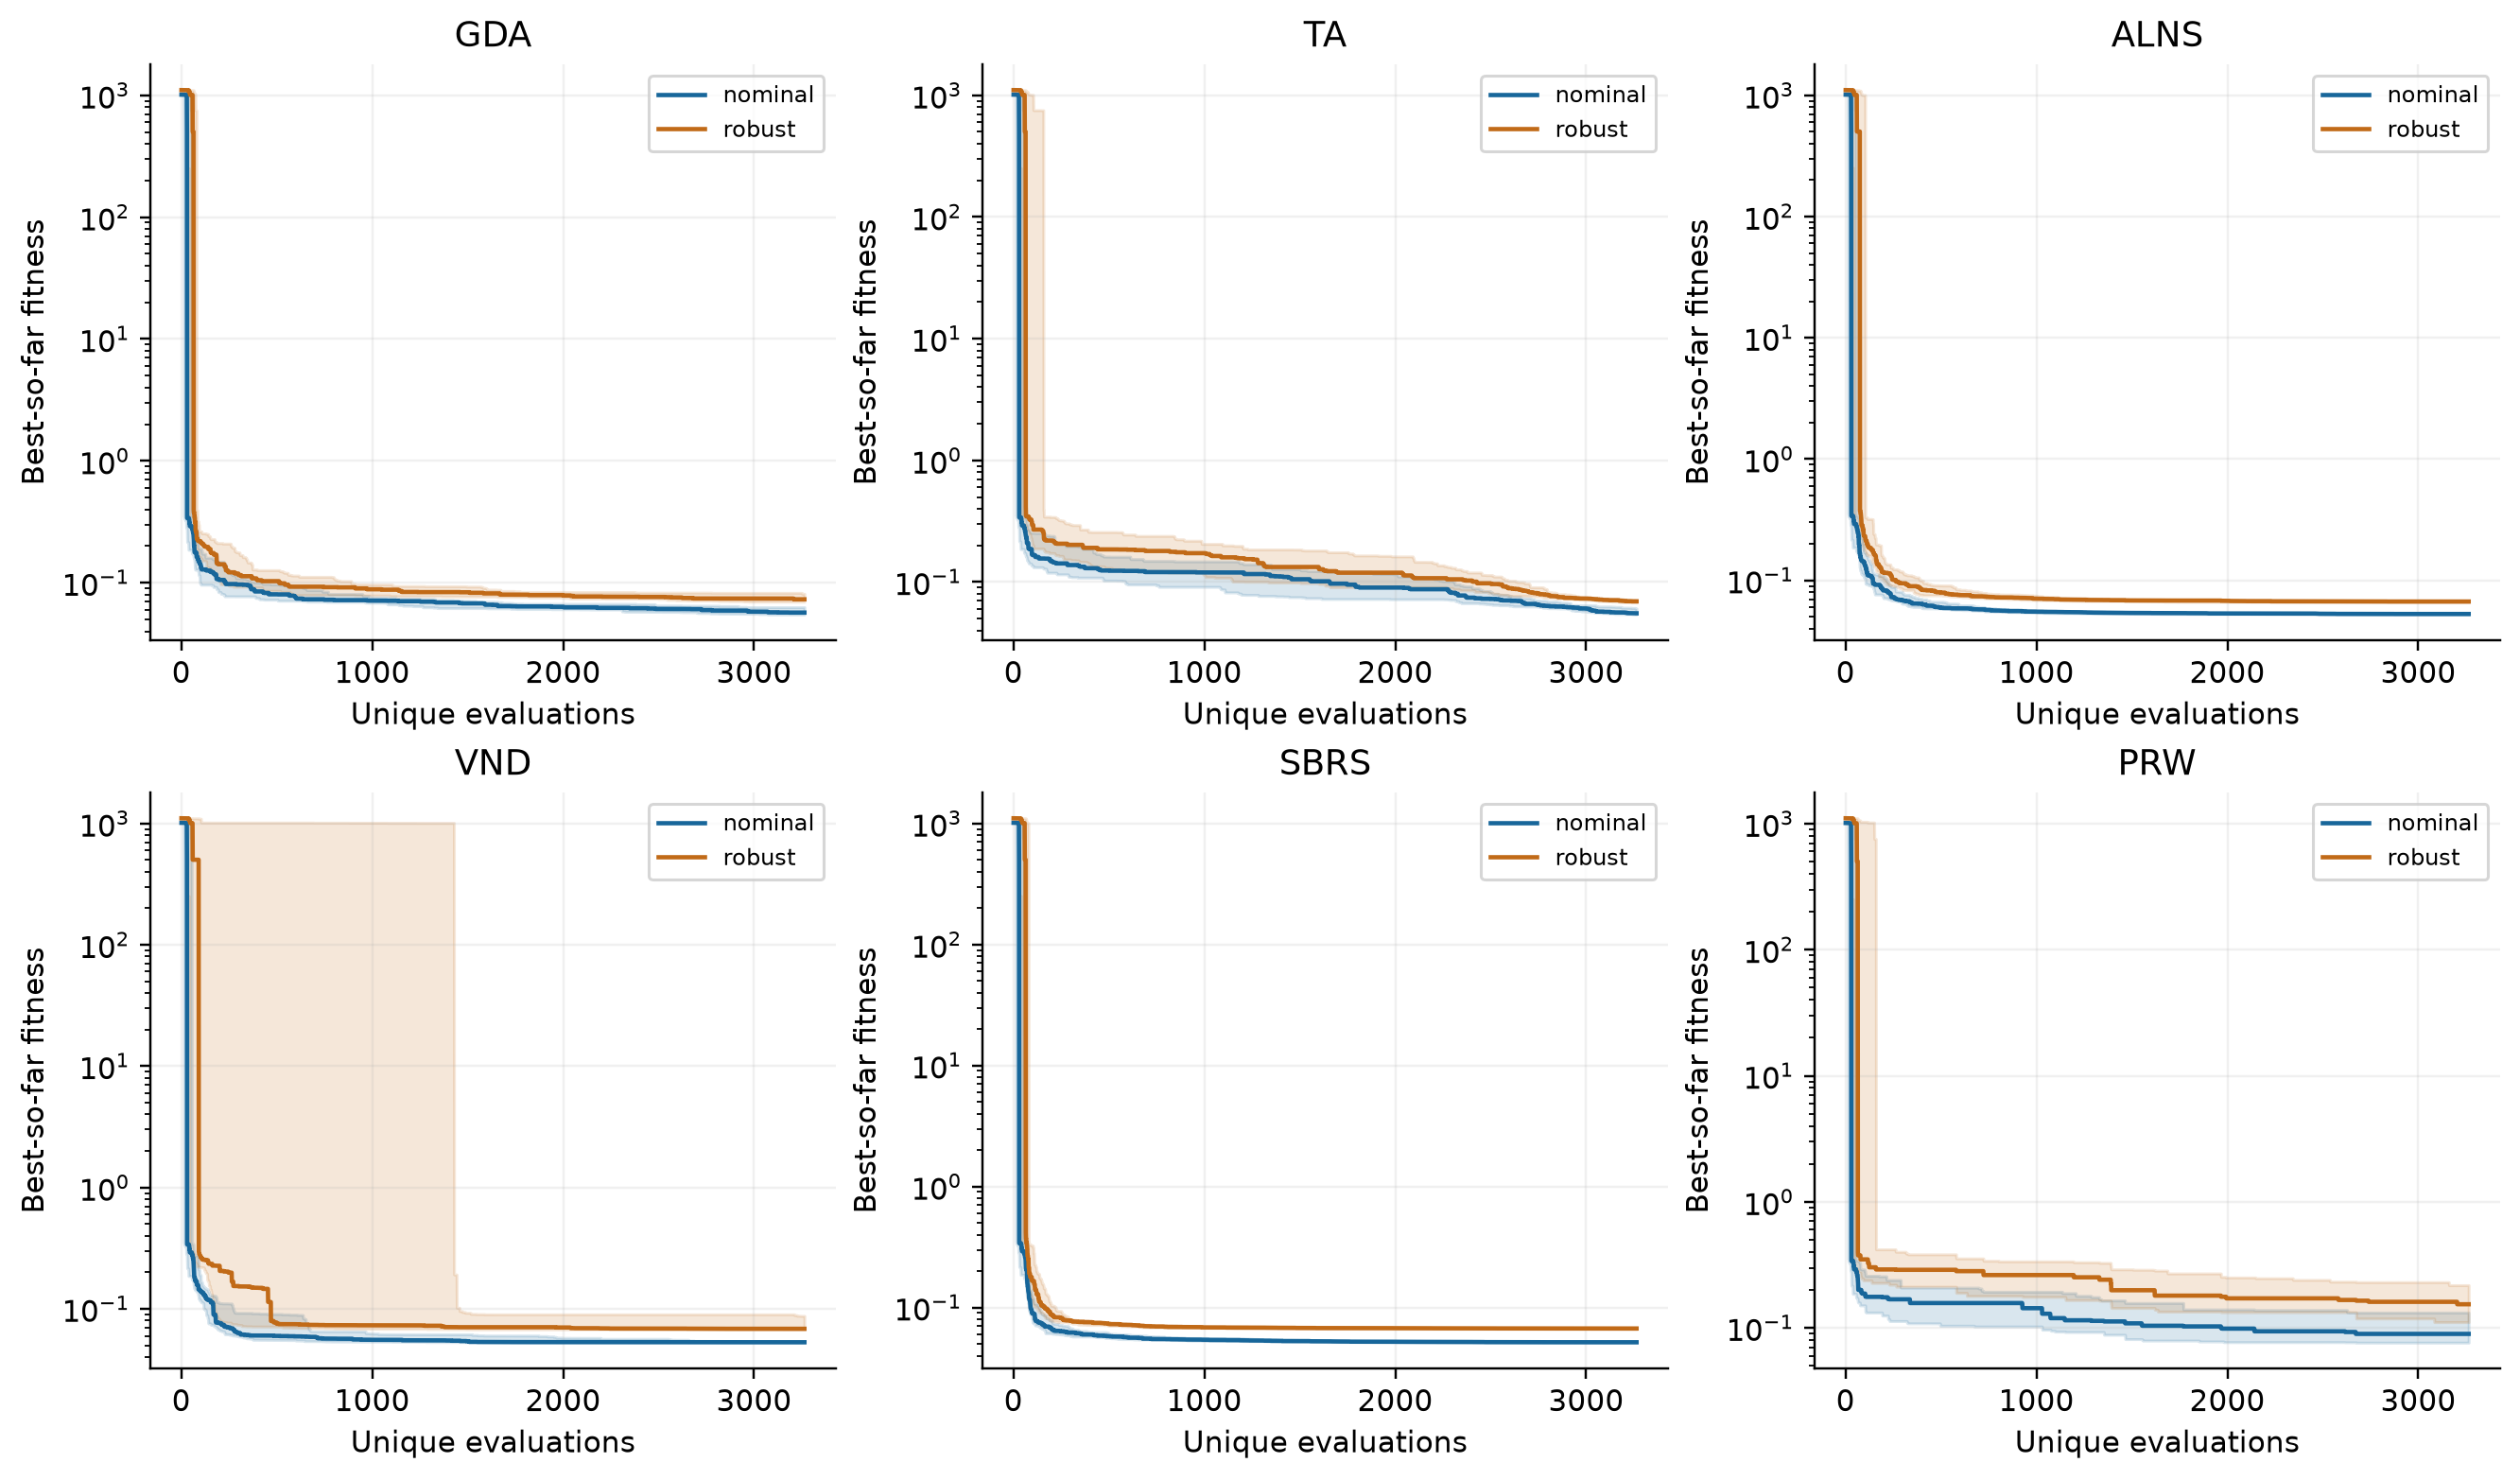

**pid using threshold accepting/results/plots/03_validation_passes.png**

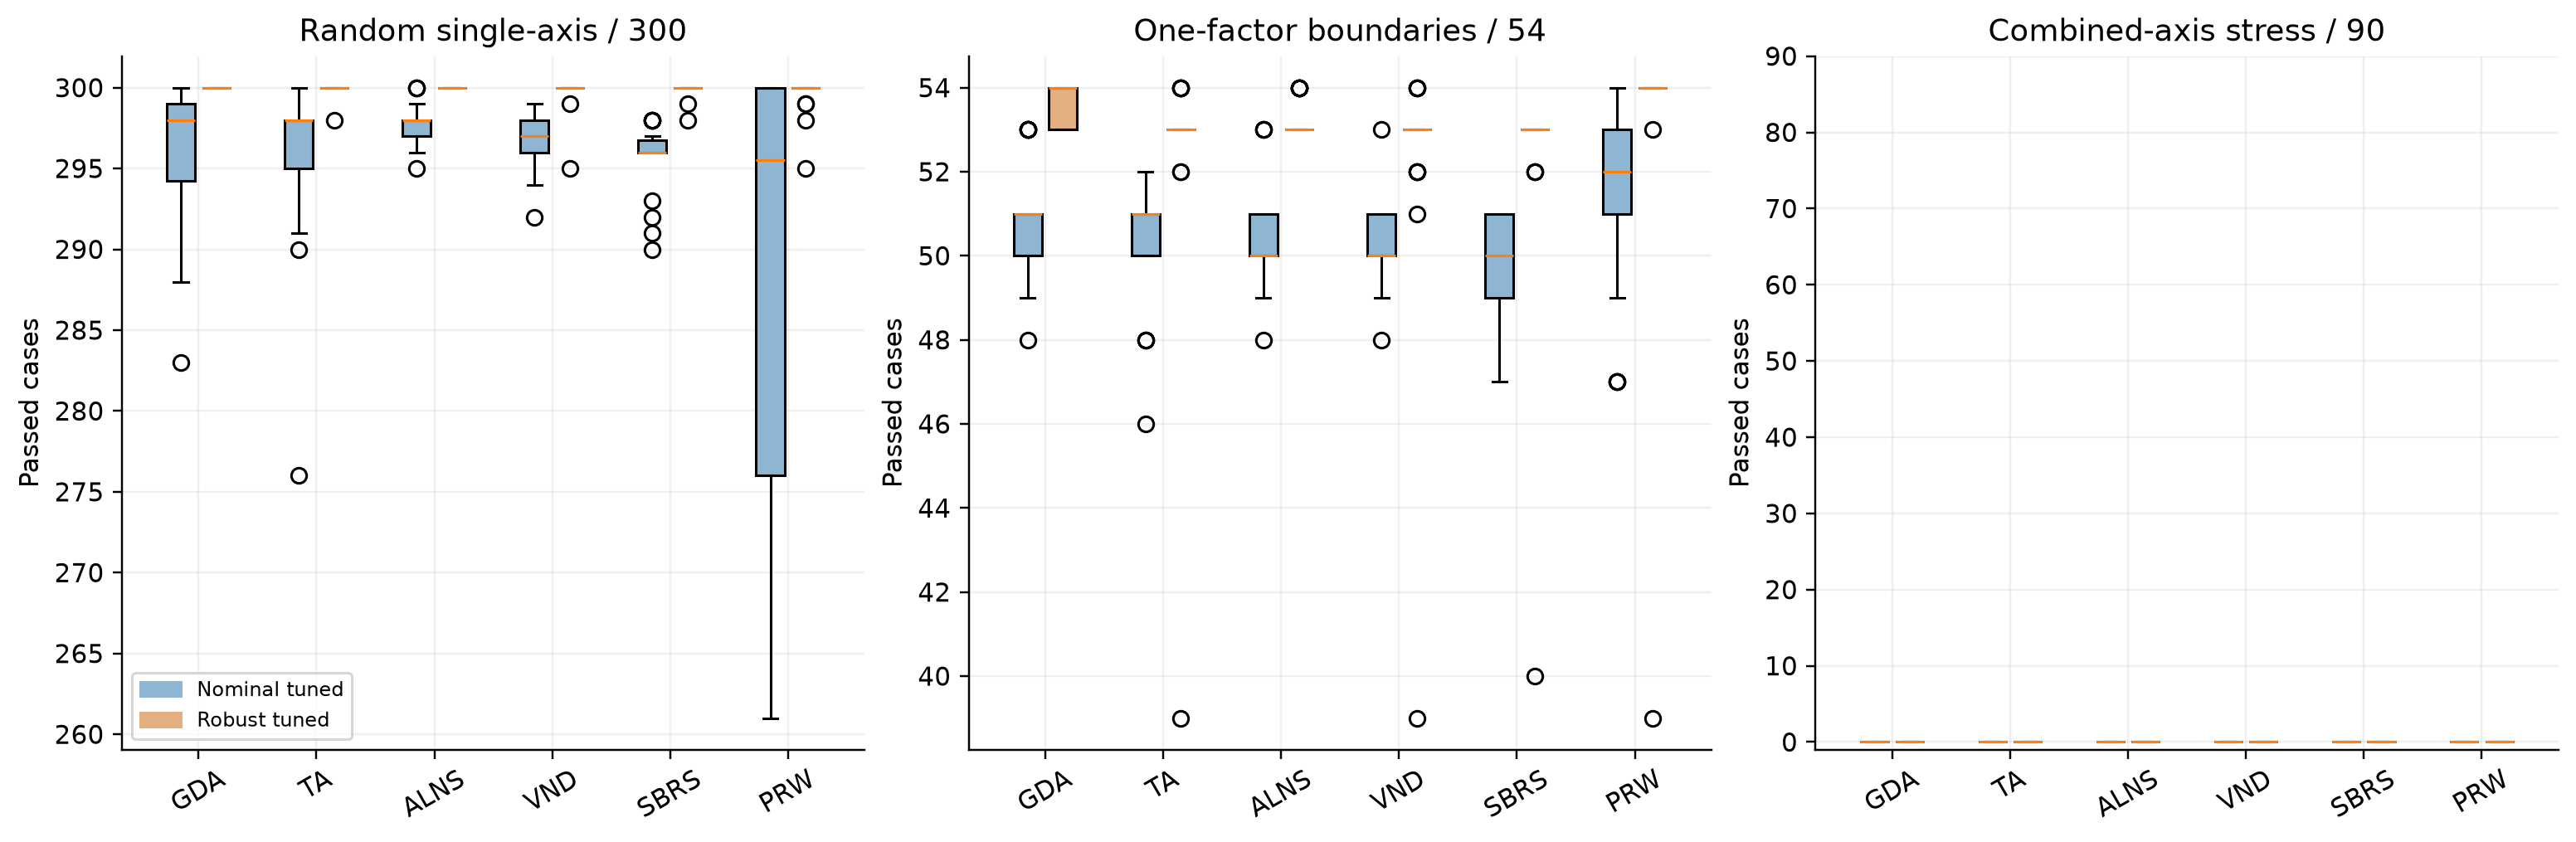

### All saved method figures
- [pid using threshold accepting/results/plots/01_fitness_distributions.png](../pid%20using%20threshold%20accepting/results/plots/01_fitness_distributions.png)
- [pid using threshold accepting/results/plots/02_convergence.png](../pid%20using%20threshold%20accepting/results/plots/02_convergence.png)
- [pid using threshold accepting/results/plots/03_validation_passes.png](../pid%20using%20threshold%20accepting/results/plots/03_validation_passes.png)
- [pid using threshold accepting/results/plots/04_speed_robustness.png](../pid%20using%20threshold%20accepting/results/plots/04_speed_robustness.png)
- [pid using threshold accepting/results/plots/05_parameter_study.png](../pid%20using%20threshold%20accepting/results/plots/05_parameter_study.png)
- [pid using threshold accepting/results/plots/06_joint_boundaries.png](../pid%20using%20threshold%20accepting/results/plots/06_joint_boundaries.png)
- [pid using threshold accepting/results/plots/07_eleven_methods.png](../pid%20using%20threshold%20accepting/results/plots/07_eleven_methods.png)
- [pid using threshold accepting/results/plots/equations/controller.png](../pid%20using%20threshold%20accepting/results/plots/equations/controller.png)
- [pid using threshold accepting/results/plots/equations/fitness.png](../pid%20using%20threshold%20accepting/results/plots/equations/fitness.png)
- [pid using threshold accepting/results/plots/equations/plant.png](../pid%20using%20threshold%20accepting/results/plots/equations/plant.png)
- [pid using threshold accepting/results/plots/TA/01_responses.png](../pid%20using%20threshold%20accepting/results/plots/TA/01_responses.png)
- [pid using threshold accepting/results/plots/TA/02_convergence.png](../pid%20using%20threshold%20accepting/results/plots/TA/02_convergence.png)
- [pid using threshold accepting/results/plots/TA/03_uncertain_responses.png](../pid%20using%20threshold%20accepting/results/plots/TA/03_uncertain_responses.png)
- [pid using threshold accepting/results/plots/TA/04_actuation.png](../pid%20using%20threshold%20accepting/results/plots/TA/04_actuation.png)
- [pid using threshold accepting/results/plots/TA/05_validation.png](../pid%20using%20threshold%20accepting/results/plots/TA/05_validation.png)
- [pid using threshold accepting/results/plots/TA/06_sensitivity.png](../pid%20using%20threshold%20accepting/results/plots/TA/06_sensitivity.png)
- [pid using threshold accepting/results/plots/TA/07_full_responses.png](../pid%20using%20threshold%20accepting/results/plots/TA/07_full_responses.png)

In [7]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [8]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from methods import optimize
params=json.loads(Path('results/selected_parameters.json').read_text())['TA']
result=optimize('TA',2026,cfg,params,out=out,limit=96)
print('Fresh 96-evaluation nominal fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../pid%20using%20threshold%20accepting/README.md) · [Data checks](../docs/DATA.md)
